### **Genetic diversity analysis - An. arabiensis population from The Gambia** -- Figure 2

In [106]:
!pip install -q malariagen_data

In [107]:
!pip install -q "plotly<6" kaleido==0.2.1

In [108]:
import os
import kaleido
import malariagen_data
import plotly.express as px
import pandas as pd

In [109]:
try:
    from google.colab import drive, output
    output.enable_custom_widget_manager()
    drive.mount("drive")
    base_dir = "drive/MyDrive/Colab Data/gm-analysis"
except ImportError:
    base_dir = "../results/gm-analysis"

results_dir = os.path.join(base_dir, "genetic_diversity-results")

Drive already mounted at drive; to attempt to forcibly remount, call drive.mount("drive", force_remount=True).


In [110]:
results_dir

'drive/MyDrive/Colab Data/gm-analysis/genetic_diversity-results'

In [111]:
git_dir = "/content/drive/My Drive/Colab Data/divergent-genetic-insecticide-resistance-in-gambian-malaria-vector"
try:
  figures_dir = os.path.join(git_dir, "figures")
except NameError:
  figures_dir = "../figures"
os.makedirs(results_dir, exist_ok=True)

In [112]:
figures_dir

'/content/drive/My Drive/Colab Data/divergent-genetic-insecticide-resistance-in-gambian-malaria-vector/figures'

In [113]:
ag3 = malariagen_data.Ag3(pre=True)
ag3

<MalariaGEN Ag3 API client>
Storage URL                           : gs://vo_agam_release_master_us_central1
Data releases available               : 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 3.10, 3.11, 3.12, 3.13, 3.14, 3.15, 3.16, 3.17
Results cache                         : None
Cohorts analysis                      : 20260120
AIM analysis                          : 20220528
Site filters analysis                 : dt_20200416
Software version                      : malariagen_data 15.10.0
Client location                       : Iowa, United States (Google Cloud us-central1)
Data filtered to unrestricted use only: False
Data filtered to surveillance use only: False
Relevant data releases                : 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 3.10, 3.11, 3.12, 3.13, 3.14, 3.15, 3.16, 3.17
---
Please note that data are subject to terms of use,
for more information see the Vector Observatory website https://www.malariagen.net/vobs/
or contact support@malariagen.net. For API documentation see 
https://malariagen.github.io/malariagen-data-python/v15.10.0/Ag3.html

In [114]:
gambia_sample_query = "country == 'Gambia, The' and sample_set == '1272-VO-GM-OPONDO-VMF00160' and taxon == 'arabiensis' and sample_id!='VBS47740-6366STDY9854349' and unrestricted_use == True"

In [115]:
# access metadata
df_samples_gambia = ag3.sample_metadata(sample_query=gambia_sample_query)
df_samples_gambia

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
0,VBS47723-6366STDY9854332,C0454,Kevin Opondo,"Gambia, The",Dongoroba,2019,9,13.380,-15.294,F,...,Mansakonko,GM-L,Jarra East,arabiensis,GM-L_arab_2019,GM-L_arab_2019_09,GM-L_arab_2019_Q3,GM-L_Jarra-East_arab_2019,GM-L_Jarra-East_arab_2019_09,GM-L_Jarra-East_arab_2019_Q3
1,VBS47725-6366STDY9854334,C2409,Kevin Opondo,"Gambia, The",Kerewan,2019,9,13.515,-14.896,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_09,GM-M_Lower-Fuladu-West_arab_2019_Q3
2,VBS47726-6366STDY9854335,C0587,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
3,VBS47729-6366STDY9854338,C2710,Kevin Opondo,"Gambia, The",Boiram,2019,10,13.503,-14.926,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_10,GM-M_arab_2019_Q4,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_10,GM-M_Lower-Fuladu-West_arab_2019_Q4
4,VBS47731-6366STDY9854340,C2524,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
309,VBS48167-6366STDY9854768,W1491,Kevin Opondo,"Gambia, The",Essau,2019,10,13.481,-16.515,F,...,Kerewan,GM-N,Lower Niumi,arabiensis,GM-N_arab_2019,GM-N_arab_2019_10,GM-N_arab_2019_Q4,GM-N_Lower-Niumi_arab_2019,GM-N_Lower-Niumi_arab_2019_10,GM-N_Lower-Niumi_arab_2019_Q4
310,VBS48171-6366STDY9854772,W2321,Kevin Opondo,"Gambia, The",Brikama-A,2019,9,13.290,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
311,VBS48173-6366STDY9854774,W0382,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
312,VBS48174-6366STDY9854775,W1168,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3


In [116]:
gambia_df = ag3.count_samples(sample_query=gambia_sample_query)
gambia_df

taxon                                                      arabiensis
country     admin1_iso admin1_name admin2_name       year            
Gambia, The GM-L       Mansakonko  Jarra East        2019           6
            GM-M       Janjanbureh Lower Fuladu West 2019          51
                                   Niamina East      2019          10
                                   Niamina West      2019           8
                                   Upper Fuladu West 2019          12
                       Kuntaur     Niani             2019           4
            GM-N       Kerewan     Illiasa           2019           3
                                   Lower Niumi       2019          13
            GM-U       Basse       Basse             2019          28
                                   Jimara            2019          37
                                   Sandu             2019           8
                                   Tumana            2019          21
                                   Wuli East         2019           1
            GM-W       Brikama     Foni Brefet       2019           1
                                   Kombo Central     2019          28
                       Kanifing    Bakau             2019           6
                                   Jeshwang          2019          77

### **Figure 2: Genetic summary statistics of An. arabiensis populations in The Gambia**

In [117]:
df_stats_admin2_gambia = ag3.diversity_stats(
    sample_query=gambia_sample_query,
    cohorts="admin2_year",
    cohort_size=10,
    region="3L:15,000,000-41,000,000",
    site_class="CDS_DEG_4",
    site_mask="gamb_colu_arab",
)

/usr/local/lib/python3.13/dist-packages/malariagen_data/anopheles.py:542: UserWarning:

Cohort (GM-L_Jarra-East_arab_2019) has insufficient samples (6) for requested cohort size (10), dropping.

/usr/local/lib/python3.13/dist-packages/malariagen_data/anopheles.py:542: UserWarning:

Cohort (GM-M_Niamina-West_arab_2019) has insufficient samples (8) for requested cohort size (10), dropping.

/usr/local/lib/python3.13/dist-packages/malariagen_data/anopheles.py:542: UserWarning:

Cohort (GM-M_Niani_arab_2019) has insufficient samples (4) for requested cohort size (10), dropping.

/usr/local/lib/python3.13/dist-packages/malariagen_data/anopheles.py:542: UserWarning:

Cohort (GM-N_Illiasa_arab_2019) has insufficient samples (3) for requested cohort size (10), dropping.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent dateti

Access SNP calls: ⠇ (0:00:30.31)

Locate CDS_DEG_4 sites:   0%|          | 0/160 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/malariagen_data/anoph/snp_data.py:1190: UserWarning:

Cohort downsampled from 51 to 10 samples. Set max_cohort_size=None to disable downsampling.



Compute SNP allele counts:   0%|          | 0/1264 [00:00<?, ?it/s]

...

Compute SNP allele counts:   0%|          | 0/1513 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/malariagen_data/anoph/snp_data.py:1190: UserWarning:

Cohort downsampled from 77 to 10 samples. Set max_cohort_size=None to disable downsampling.



Compute SNP allele counts:   0%|          | 0/1265 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/malariagen_data/anoph/snp_data.py:1190: UserWarning:

Cohort downsampled from 28 to 10 samples. Set max_cohort_size=None to disable downsampling.



Compute SNP allele counts:   0%|          | 0/1261 [00:00<?, ?it/s]

In [118]:
df_stats_admin2_gambia

,cohort,theta_pi,theta_pi_estimate,theta_pi_bias,theta_pi_std_err,theta_pi_ci_err,theta_pi_ci_low,theta_pi_ci_upp,theta_w,theta_w_estimate,...,tajima_d_ci_upp,taxon,year,month,country,admin1_iso,admin1_name,admin2_name,longitude,latitude
0,GM-M_Lower-Fuladu-West_arab_2019,0.014193,0.014193,2.238102e-08,0.000232,0.000909,0.013739,0.014648,0.019449,0.019448,...,-1.089994,arabiensis,2019,"[9, 10, 11]","Gambia, The",GM-M,Janjanbureh,Lower Fuladu West,-14.902039,13.530882
1,GM-M_Niamina-East_arab_2019,0.014482,0.014480,2.125570e-06,0.000231,0.000904,0.014028,0.014932,0.020270,0.020263,...,-1.157986,arabiensis,2019,"[9, 12]","Gambia, The",GM-M,Janjanbureh,Niamina East,-15.157000,13.619500
2,GM-M_Upper-Fuladu-West_arab_2019,0.013595,0.013594,3.480166e-07,0.000232,0.000908,0.013140,0.014048,0.017793,0.017795,...,-0.945120,arabiensis,2019,9,"Gambia, The",GM-M,Janjanbureh,Upper Fuladu West,-14.655000,13.434000
3,GM-N_Lower-Niumi_arab_2019,0.013401,0.013400,1.199394e-06,0.000233,0.000912,0.012944,0.013856,0.016860,0.016857,...,-0.815360,arabiensis,2019,10,"Gambia, The",GM-N,Kerewan,Lower Niumi,-16.515000,13.481000
4,GM-U_Basse_arab_2019,0.013572,0.013571,3.223275e-07,0.000231,0.000907,0.013118,0.014025,0.017847,0.017847,...,-0.961326,arabiensis,2019,9,"Gambia, The",GM-U,Basse,Basse,-14.205750,13.269286
5,GM-U_Jimara_arab_2019,0.013483,0.013481,1.644813e-06,0.000237,0.000931,0.013016,0.013947,0.017672,0.017669,...,-0.951968,arabiensis,2019,"[9, 10]","Gambia, The",GM-U,Basse,Jimara,-14.324162,13.275973
6,GM-U_Tumana_arab_2019,0.013965,0.013961,3.530969e-06,0.000230,0.000902,0.013511,0.014412,0.018837,0.018831,...,-1.042728,arabiensis,2019,"[10, 11, 12]","Gambia, The",GM-U,Basse,Tumana,-14.049190,13.355952
7,GM-W_Jeshwang_arab_2019,0.013248,0.013247,1.768183e-06,0.000227,0.000888,0.012802,0.013691,0.016488,0.016487,...,-0.775591,arabiensis,2019,9,"Gambia, The",GM-W,Kanifing,Jeshwang,-16.670987,13.437247
8,GM-W_Kombo-Central_arab_2019,0.015076,0.015074,1.466039e-06,0.000234,0.000918,0.014615,0.015533,0.021418,0.021414,...,-1.200445,arabiensis,2019,9,"Gambia, The",GM-W,Brikama,Kombo Central,-16.657000,13.290000


In [119]:
df_stats_admin2_gambia.columns

Index(['cohort', 'theta_pi', 'theta_pi_estimate', 'theta_pi_bias',
       'theta_pi_std_err', 'theta_pi_ci_err', 'theta_pi_ci_low',
       'theta_pi_ci_upp', 'theta_w', 'theta_w_estimate', 'theta_w_bias',
       'theta_w_std_err', 'theta_w_ci_err', 'theta_w_ci_low', 'theta_w_ci_upp',
       'tajima_d', 'tajima_d_estimate', 'tajima_d_bias', 'tajima_d_std_err',
       'tajima_d_ci_err', 'tajima_d_ci_low', 'tajima_d_ci_upp', 'taxon',
       'year', 'month', 'country', 'admin1_iso', 'admin1_name', 'admin2_name',
       'longitude', 'latitude'],
      dtype='object')

In [120]:
########## Plot the genetic diversity estimators summary
def plot_diversity_stats(
    df_stats_admin2_gambia,
    color=None,
    height=450,
    template="plotly_white"
):

    # set up common plotting parameters
    hover_name = "cohort"
    hover_data = [
        "taxon",
        "country",
        "admin1_iso",
        "admin1_name",
        "admin2_name",
        "year",
        "month",
    ]
    labels = {
        'theta_pi_estimate': r'$\widehat{\theta}_{\pi}$',
        'theta_w_estimate': r'$\widehat{\theta}_{w}$',
        'tajima_d_estimate': r'$D$',
        'cohort': "Cohort",
        'taxon': 'Taxon',
        'country': "Country",
        "admin2_name": "Location"
    }
    color_mapping_admin2 = {
    "Jeshwang": "#a4c9e2",
    "Kombo Central": "#78aaff",
    "Lower Niumi": "#4d88ff",
    "Niamina East": "#3b5c40",
    "Lower Fuladu West": "#7f7f7f",
    "Upper Fuladu West": "#6b705c",
    "Jimara": "#8e7d32",
    "Basse": "#a95b29",
    "Tumana": "#8a4b39"
    }
    width = 300 + 30 * len(df_stats_admin2_gambia)

    # Fig 2A : Nucleotide diversity bar plot
    fig2a = px.bar(
        data_frame=df_stats_admin2_gambia,
        x="cohort",
        y="theta_pi_estimate",
        error_y="theta_pi_ci_err",
        title="Nucleotide diversity",
        color=color,
        color_discrete_map=color_mapping_admin2,
        height=height,
        width=width,
        hover_name=hover_name,
        hover_data=hover_data,
        labels=labels,
        template=template
    )
    fig2a.show(renderer="png")
    fig2a.write_image(
    os.path.join(figures_dir, "fig2a_nucleotide_diversity.png"),
    format="png",
    scale=2
)

    # Figure 2 B : Watterson estimator bar plot
    fig2b = px.bar(
        data_frame=df_stats_admin2_gambia,
        x="cohort",
        y="theta_w_estimate",
        error_y="theta_w_ci_err",
        title="Watterson estimator",
        color=color,
        color_discrete_map=color_mapping_admin2,
        height=height,
        width=width,
        hover_name=hover_name,
        hover_data=hover_data,
        labels=labels,
        template=template
    )
    fig2b.show(renderer="png")
    fig2b.write_image(
    os.path.join(figures_dir, "fig2b_watterson_estimator.png"),
    format="png",
    scale=2
    )

    # Figure 2C : Tajima's d bar plot
    fig2c = px.bar(
        data_frame=df_stats_admin2_gambia,
        x="cohort",
        y="tajima_d_estimate",
        error_y="tajima_d_ci_err",
        title="Tajima's D",
        color=color,
        color_discrete_map=color_mapping_admin2,
        height=height,
        width=width,
        hover_name=hover_name,
        hover_data=hover_data,
        labels=labels,
        template=template
    )
    fig2c.show(renderer="png")
    fig2c.write_image(
    os.path.join(figures_dir, "fig2c_tajima_D.png"),
    format="png",
    scale=2
    )

    # Figure 2D : Scatter plot comparing diversity estimators
    fig2d = px.scatter(
        data_frame=df_stats_admin2_gambia,
        x="theta_pi_estimate",
        y="theta_w_estimate",
        error_x="theta_pi_ci_err",
        error_y="theta_w_ci_err",
        title="Diversity estimators",
        color=color,
        color_discrete_map=color_mapping_admin2,
        width=500,
        height=500,
        hover_name=hover_name,
        hover_data=hover_data,
        labels=labels,
        template=template
    )
    fig2d.show(renderer="png")
    fig2d.write_image(
    os.path.join(figures_dir, "fig2d_diversity_estimator.png"),
    format="png",
    scale=2
    )

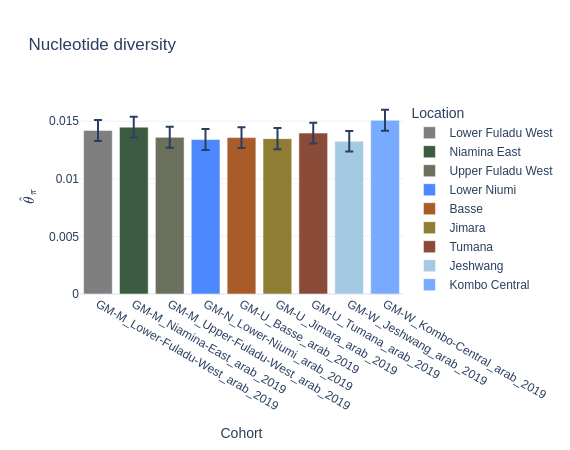

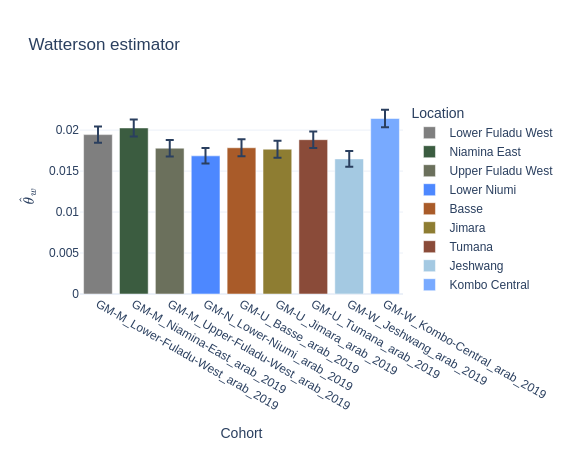

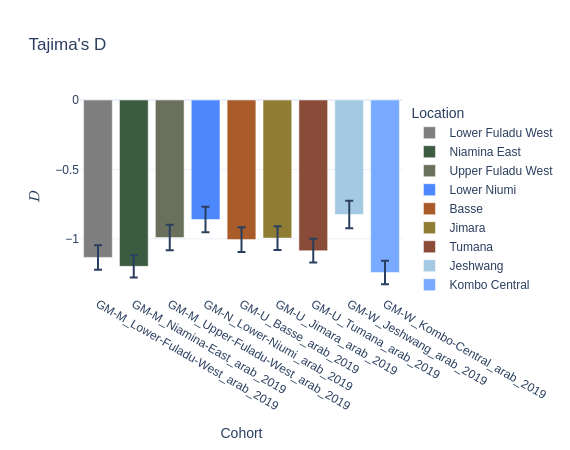

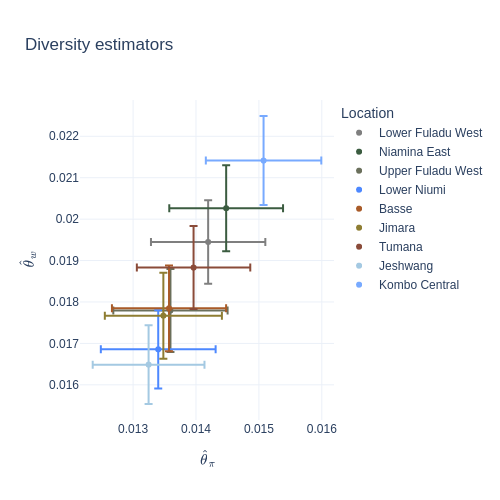

In [121]:
plot_diversity_stats(df_stats_admin2_gambia, color="admin2_name")

### ** order regions by longitude from west to east (aka coastal to inland regions) **

- set order and index

In [122]:
arab_region = (
    df_samples_gambia
    .pivot_table(
        index={"admin2_name"},
        columns="taxon",
        values="sample_id",
        aggfunc="count",
        fill_value=0
    )
)
arab_region

taxon,arabiensis
admin2_name,
Bakau,6
Basse,28
Foni Brefet,1
Illiasa,3
Jarra East,6
Jeshwang,77
Jimara,37
Kombo Central,28
Lower Fuladu West,51


In [123]:
# order regions by longitude
df_gambia_admin2 = (
    df_samples_gambia
    .groupby("admin2_name")
    .aggregate({
        "longitude": "mean"})
    .sort_values("longitude")
)
df_gambia_admin2

,longitude
admin2_name,
Bakau,-16.674000
Jeshwang,-16.670987
Kombo Central,-16.657000
Lower Niumi,-16.515000
Foni Brefet,-16.414000
Illiasa,-15.599000
Jarra East,-15.294000
Niamina West,-15.233000
Niamina East,-15.157000


In [124]:
gambia_admin2 = df_gambia_admin2.index.tolist()
gambia_admin2

['Bakau',
 'Jeshwang',
 'Kombo Central',
 'Lower Niumi',
 'Foni Brefet',
 'Illiasa',
 'Jarra East',
 'Niamina West',
 'Niamina East',
 'Niani',
 'Lower Fuladu West',
 'Upper Fuladu West',
 'Jimara',
 'Sandu',
 'Basse',
 'Wuli East',
 'Tumana']

In [125]:
df_stats_admin2_longitude = (
    df_stats_admin2_gambia
    .query("taxon == 'arabiensis'")
    .sort_values("longitude")
    .reset_index()
)
df_stats_admin2_longitude

,index,cohort,theta_pi,theta_pi_estimate,theta_pi_bias,theta_pi_std_err,theta_pi_ci_err,theta_pi_ci_low,theta_pi_ci_upp,theta_w,...,tajima_d_ci_upp,taxon,year,month,country,admin1_iso,admin1_name,admin2_name,longitude,latitude
0,7,GM-W_Jeshwang_arab_2019,0.013248,0.013247,1.768183e-06,0.000227,0.000888,0.012802,0.013691,0.016488,...,-0.775591,arabiensis,2019,9,"Gambia, The",GM-W,Kanifing,Jeshwang,-16.670987,13.437247
1,8,GM-W_Kombo-Central_arab_2019,0.015076,0.015074,1.466039e-06,0.000234,0.000918,0.014615,0.015533,0.021418,...,-1.200445,arabiensis,2019,9,"Gambia, The",GM-W,Brikama,Kombo Central,-16.657000,13.290000
2,3,GM-N_Lower-Niumi_arab_2019,0.013401,0.013400,1.199394e-06,0.000233,0.000912,0.012944,0.013856,0.016860,...,-0.815360,arabiensis,2019,10,"Gambia, The",GM-N,Kerewan,Lower Niumi,-16.515000,13.481000
3,1,GM-M_Niamina-East_arab_2019,0.014482,0.014480,2.125570e-06,0.000231,0.000904,0.014028,0.014932,0.020270,...,-1.157986,arabiensis,2019,"[9, 12]","Gambia, The",GM-M,Janjanbureh,Niamina East,-15.157000,13.619500
4,0,GM-M_Lower-Fuladu-West_arab_2019,0.014193,0.014193,2.238102e-08,0.000232,0.000909,0.013739,0.014648,0.019449,...,-1.089994,arabiensis,2019,"[9, 10, 11]","Gambia, The",GM-M,Janjanbureh,Lower Fuladu West,-14.902039,13.530882
5,2,GM-M_Upper-Fuladu-West_arab_2019,0.013595,0.013594,3.480166e-07,0.000232,0.000908,0.013140,0.014048,0.017793,...,-0.945120,arabiensis,2019,9,"Gambia, The",GM-M,Janjanbureh,Upper Fuladu West,-14.655000,13.434000
6,5,GM-U_Jimara_arab_2019,0.013483,0.013481,1.644813e-06,0.000237,0.000931,0.013016,0.013947,0.017672,...,-0.951968,arabiensis,2019,"[9, 10]","Gambia, The",GM-U,Basse,Jimara,-14.324162,13.275973
7,4,GM-U_Basse_arab_2019,0.013572,0.013571,3.223275e-07,0.000231,0.000907,0.013118,0.014025,0.017847,...,-0.961326,arabiensis,2019,9,"Gambia, The",GM-U,Basse,Basse,-14.205750,13.269286
8,6,GM-U_Tumana_arab_2019,0.013965,0.013961,3.530969e-06,0.000230,0.000902,0.013511,0.014412,0.018837,...,-1.042728,arabiensis,2019,"[10, 11, 12]","Gambia, The",GM-U,Basse,Tumana,-14.049190,13.355952


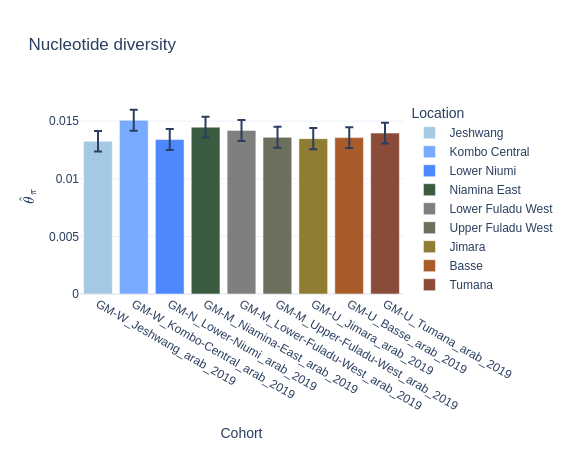

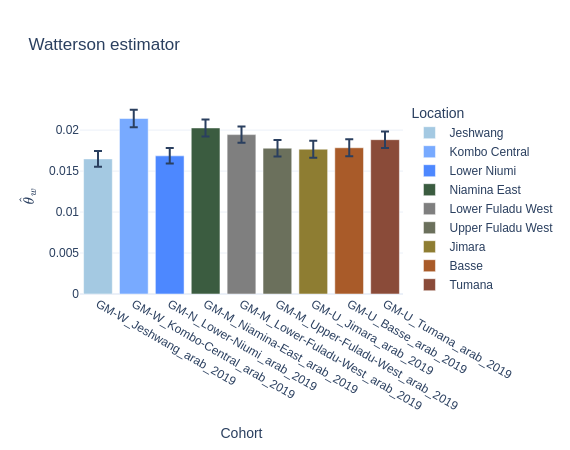

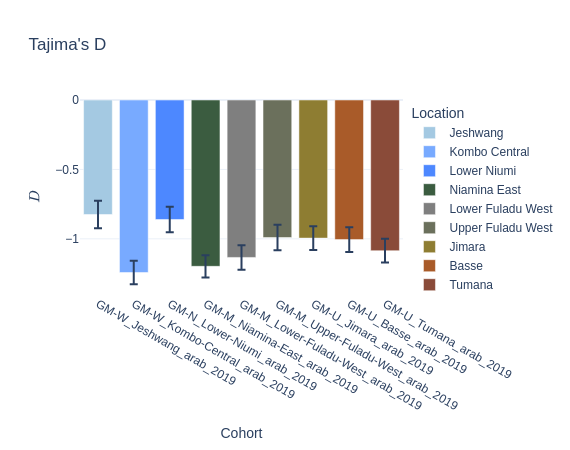

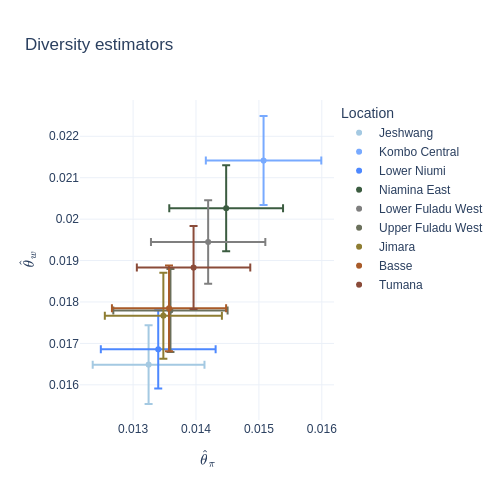

In [126]:
plot_diversity_stats(df_stats_admin2_longitude, color="admin2_name")